

# Regression task

**Task 1.** Download a set of video game sales data in CSV format and upload it to a dataframe.

[Link to the data](https://www.dropbox.com/s/8nud70nncbxpgh1/videogames.csv?dl=1)

Take the volume of global sales as the target variable. With the help of a scattering diagram, select such a single factorial feature, the relationship of which with the target is closest to linear.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("https://www.dropbox.com/s/8nud70nncbxpgh1/videogames.csv?dl=1")
df.head(3)

,Rank,Name,Platform,Year,Genre,Publisher,NorthAmerica_Sales,EurpeanUnion_Sales,Japan_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,NaN,12.88,3.79,NaN,35.82


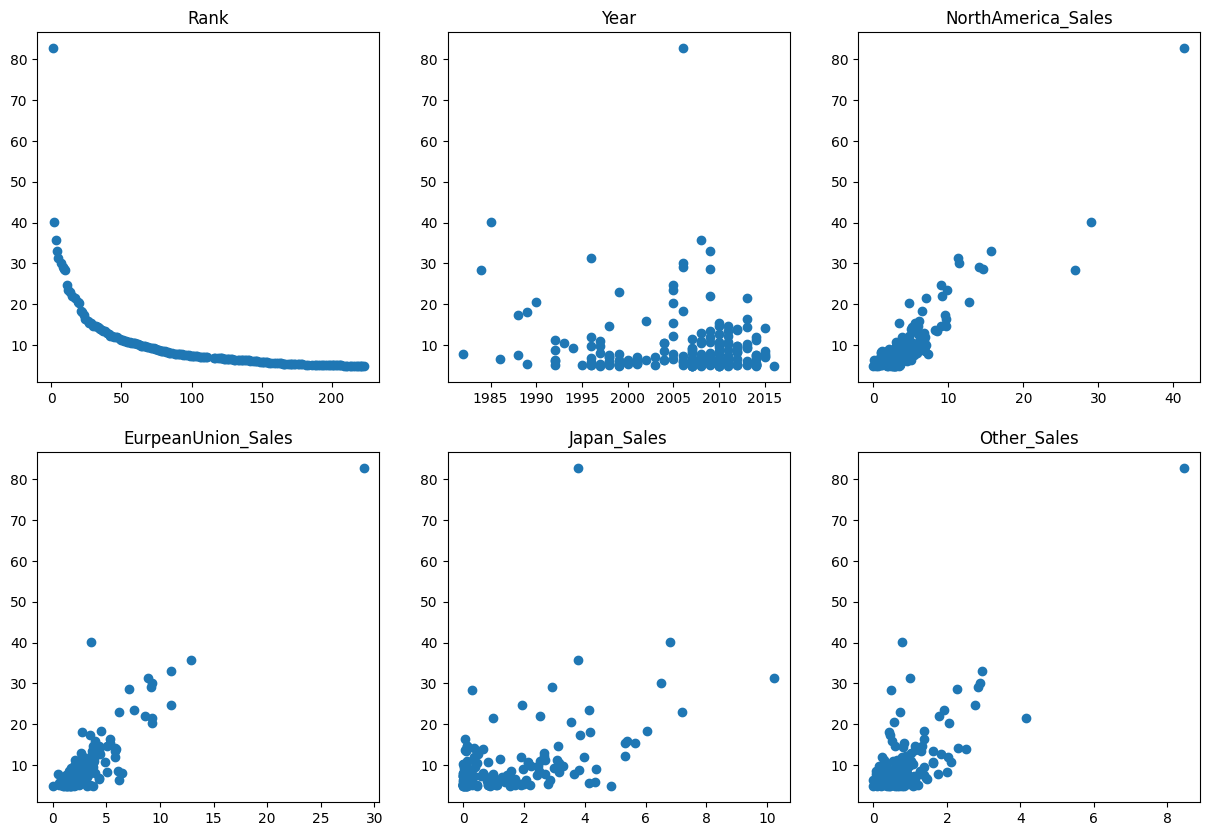

In [2]:
# Task: With the help of a scattering diagram, select such a one (for simplicity) factorial feature, 
# the relationship of which with the target is closest to linear. Building a "paired linear regression model"

plt.rcParams["figure.figsize"] = 15, 10  # width, height

i_graph = 1  # cell number in the grid (starts with 1)
# sorting by numeric columns (except target)
for i in [0, 3, 6, 7, 8, 9]:
  colname = df.columns[i] # go to the list of columns df.columns
  plt.subplot(2, 3, i_graph)  # we indicate that we are putting the graph in a grid 2*3
  plt.scatter(x=df[colname], y=df.Global_Sales)  # building a dependency graph Global_Sales on the current column
  plt.title(colname)  # adding a name as the name of the current column
  i_graph += 1

In [3]:
# So, we are more or less close to "linear dependence"  
# dependencies NorthAmerica_Sales and EurpeanUnion_Sales от Global_Sales. Let's take just NorthAmerica_Sales
# BOTTOM LINE: we are building a model of paired linear regression dependence Global_Sales(target attribute) from NorthAmerica_Sales(factorial feature)

**Task 2.** Divide the sample into training and test in a ratio of 8 to 2, after mixing.

In [4]:
# since regression is a kind of machine learning with a teacher, the model needs to be trained (a training sample is needed),
# and then check if she has learned well (on a test sample), where only we know the answers (true values), 
# and the model does not know this (she did not study with them). She will predict by them

# Why mix it all up? we have data sorted by the size of global sales. The training data should be as independent of each other as possible

In [5]:
# So, let's split the sample into training and test, save the indexes

# method .sample() сby default, one line is randomly extracted. If all the lines are like this, then n = len(df)
random_index = df.sample(n=len(df)).index # got mixed indexes of all rows


train_index = random_index[:int(len(df) * 0.8)] # the first 0 to 80% of their list of shuffled indexes
test_index = random_index[int(len(df) * 0.8):] # the remaining 20% (from 80% to the end)

In [6]:
test_index

Int64Index([173, 143,  79,  76,  15,  67, 196,  54, 172, 194, 155, 166,  33,
            115, 107, 184, 197,  31, 123,  87,  70, 110,  92,  36,  25,  77,
             24, 104,   2,  35, 185,  17,  10,  53,  91, 182, 151, 112,  80,
            186],
           dtype='int64')

**Task 3.** To construct a model of paired linear regression of the target feature (Y) by factor feature (X). The model must be trained on a training sample. Make an interpretation of the coefficients of the model. Plot a dot graph (Y versus X dependence) for the training sample and plot a regression line. Calculate the coefficient of determination $R^2$ on the training sample.

$R^2=1-\frac{RSS}{TSS}$

$RSS=∑(y-\hat{y})^2$

$TSS=∑(y-\bar{y})^2$

In [7]:
# we will eliminate the empty values, otherwise MNC will not work in LinearRegression
df.interpolate(inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                199 non-null    int64  
 1   Name                199 non-null    object 
 2   Platform            199 non-null    object 
 3   Year                199 non-null    int64  
 4   Genre               199 non-null    object 
 5   Publisher           198 non-null    object 
 6   NorthAmerica_Sales  199 non-null    float64
 7   EurpeanUnion_Sales  199 non-null    float64
 8   Japan_Sales         199 non-null    float64
 9   Other_Sales         199 non-null    float64
 10  Global_Sales        199 non-null    float64
dtypes: float64(5), int64(2), object(4)
memory usage: 17.2+ KB


In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

y_col = "Global_Sales"  # target attribute
x_col = ["NorthAmerica_Sales"]  # factor signs

model = LinearRegression().fit(X=df.loc[train_index, x_col],
                               y=df.loc[train_index, y_col])
# method .fit() from the English "adapt, fit" (in our case, "train")
    # 1. we pass a data frame\series with a factor column with indexes corresponding to the training sample 
    # (or you may have a dataset with multiple icons, so a big icon "X=")
    # that is, the indexes of the rows of the training sample and the column itself with the factorial feature
    # 2. target variable (a small letter "y="", because she's lonely!)
print(f"Model coefficients: {model.coef_}, free member: {model.intercept_}")
# we have a "paired linear regression model", so the coefficient for X is the only one. The values can be different, i.e. we take a random training sample 

Model coefficients: [1.6094105], free member: 2.1985728750793134


$\hat{y}=1,5814x+2,2199$

Interpretation:

If $x$ changes by 1, then $y$ will change in the same direction by 1.5814.

If $x=0$ then $y$ will be 2,2199.

In [9]:
# What does a free member show? with sales in North America x=0, global sales will be 2,2199
# What does the coefficient show? With sales in North America increasing by 1, global sales increase by 1,58

In [10]:
# we will get the model values ("predicted" /"predicted") on the training sample
y_model = model.predict(df.loc[train_index, x_col]) # that is, we will get a new model "y" on the training sample

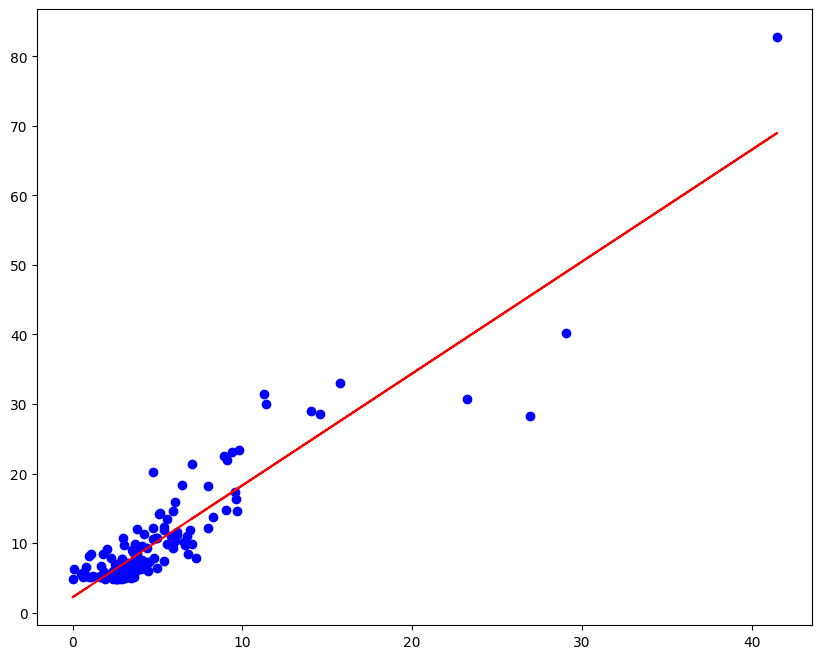

In [11]:
plt.rcParams["figure.figsize"] = 10, 8  # width, height

# let's build a scatter plot (on a training sample) 
plt.scatter(x=df.loc[train_index, x_col], y=df.loc[train_index, y_col], color="blue")
# and draw a regression line
plt.plot(df.loc[train_index, x_col], y_model, color="red");

# backfill question: we ordered y by x, why is the line straight, and not zigzags, as in work 9?
# answer: because all the points of the model lie on a straight line

**Task 3(b).** Calculate the coefficient of determination $R^2$ on the training sample.

$R^2=1-\frac{RSS}{TSS}$

$RSS=∑(y-\hat{y})^2$

$TSS=∑(y-\bar{y})^2$

In [12]:
# manually calculate the "coefficient of determination" on the training sample 
# RSS (Residual Sum of Squares, the explained sum of squared deviations) - we subtract the predicted values from each actual sample value, then square them, and then add
# TSS (Total Sum of Squares, total sum of squared deviations) - ... subtract the average value
R2 = 1 - sum((df.loc[train_index, y_col] - y_model) ** 2) / \
  sum((df.loc[train_index, y_col] - df.loc[train_index, y_col].mean()) ** 2)

print(R2)

# Interpretation: The model turned out to be good! because the closer the coefficient value is to 1, the stronger the dependence

0.8474586796984697


In [13]:
# and now let's calculate the "coefficient of determination" using the library function
import sklearn.metrics as metrics

metrics.r2_score(df.loc[train_index, y_col], y_model)
# 1 parameter: true values, 2 parameter: predicted values

0.8474586796984697

**Task 4.** You can evaluate the quality of the constructed model on a test sample using the indicators $R^2$ and $RMSE$. Build a scatter chart for all the data and build a regression line by coloring the points of the training and test samples with different colors.

In [14]:
# Let's check how the model behaves on a test sample, i.e. on data that it has not seen.
# So, we get the predicted (model) values on the test sample
y_pred = model.predict(df.loc[test_index, x_col])

In [15]:
print("R2 =", metrics.r2_score(df.loc[test_index, y_col], y_pred)) # for a test sample
print("RMSE (Root Mean Squared Error)=", metrics.mean_squared_error(df.loc[test_index, y_col], y_pred) ** 0.5)
# the MSE function works without a square root, let's write it down manually

# а) R2 - R - square the coefficient of determination. The closer the coefficient value is to 1, the stronger the dependence

# б) Root of Mean square Error (RMSE) measures the average difference between the values, 
# predicted by the prediction model and the actual values.

# Interpretation: The R-square has become slightly smaller in the test sample, but also not bad

R2 = 0.8217241561987829
RMSE (Root Mean Squared Error)= 2.7126033435537726


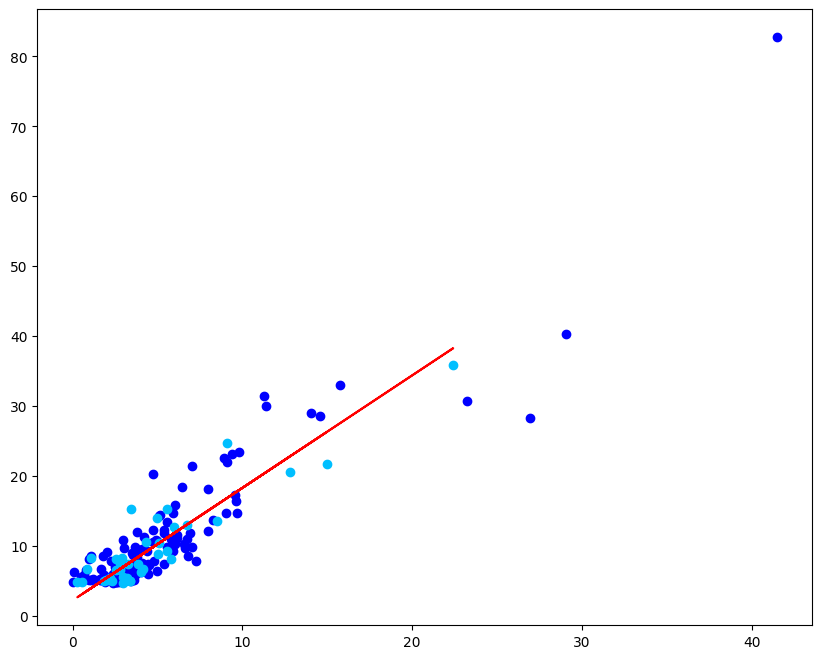

In [16]:
# let's build a scattering diagram and plot a regression line
plt.scatter(x=df.loc[train_index, x_col], y=df.loc[train_index, y_col], color="blue")  # training
plt.scatter(x=df.loc[test_index, x_col], y=df.loc[test_index, y_col], color="deepskyblue");  # test
#plt.plot(df.loc[train_index, x_col], y_model, color="red") # training
plt.plot(df.loc[test_index, x_col], y_pred, color="red") # test

**Task 5.** *Тnow let's move on to multiple regression.* First, you need to perform a correlation analysis of all numeric columns and select 3 such factor columns that:
* have the greatest correlation with the target column;
* they have the least correlation with each other.

In [17]:
# A) correlation with the "target feature", the columns are ordered modulo the Pearson correlation coefficient
df.corr()[y_col].iloc[:-1].abs().sort_values()

# parsing the expression that stands above:
# 1. df.corr() # builds a correlation matrix for all numeric columns
# 2. df.corr()[y_col] # we select only 1 column containing the correlation coefficient of all the other columns 
# with the target (recall that y_col = "Global_Sales"). as a result, we get a "series"
# 3. df.corr()[y_col].iloc[:-1] we make a slice by throwing out the last row, because the correlation itself = 1
# 4. take the module and sort
# result: the correlation between the last three rows and the target value is the best (Global_Sales)
# the Year attribute has almost no effect on the target variable, you can discard it

<ipython-input-17-347251a9cf92>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()[y_col].iloc[:-1].abs().sort_values()


Year                  0.094701
Japan_Sales           0.530805
Rank                  0.680544
Other_Sales           0.748527
EurpeanUnion_Sales    0.880777
NorthAmerica_Sales    0.919031
Name: Global_Sales, dtype: float64

In [18]:
# B) now we are looking for the smallest correlation of factor features

# let's go through all the paired combinations of columns, calculate the correlation coefficient for each
# and write down the values in a series
import itertools
import scipy.stats as stats
corr_ser = pd.Series()
for pair in itertools.combinations(df.columns[[0, 3, 6, 7, 8, 9]], r=2):
  col1, col2 = pair
  corr_ser.loc[f"{col1}-{col2}"] = stats.pearsonr(df[col1], df[col2])[0]

# or you can use correlation analysis 

<ipython-input-18-10dd420f90e5>:7: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  corr_ser = pd.Series()


In [19]:
# let's sort the pairs of features modulo the correlation coefficient
corr_ser.abs().sort_values()

Rank-Year                                0.009602
Year-EurpeanUnion_Sales                  0.109275
Japan_Sales-Other_Sales                  0.138066
Year-NorthAmerica_Sales                  0.219009
Year-Japan_Sales                         0.298666
EurpeanUnion_Sales-Japan_Sales           0.338986
Year-Other_Sales                         0.339671
NorthAmerica_Sales-Japan_Sales           0.367145
Rank-Japan_Sales                         0.469497
Rank-Other_Sales                         0.481595
NorthAmerica_Sales-Other_Sales           0.560283
Rank-EurpeanUnion_Sales                  0.587106
Rank-NorthAmerica_Sales                  0.601284
NorthAmerica_Sales-EurpeanUnion_Sales    0.709170
EurpeanUnion_Sales-Other_Sales           0.854637
dtype: float64

In [20]:
# Interpretation: 

# Let's choose only the following signs Japan, Other, NorthAmerica
# (why these ones? they don't have the highest cross-correlation 
# and not the lowest correlation with the target feature). 

# But European Union_Sales, although it has a good correlation with the goal, is strongly related to the rest of the factor indicators - this is multicollenarity
# Ideal for good factor variables for a regression problem: high correlation with the goal and low with the rest of the factorial

**Task 6.** To build a model of multiple linear regression on a training sample. Evaluate its quality on a test sample.

In [21]:
y_col = "Global_Sales"  # target attribute
X_cols = ["NorthAmerica_Sales", "Japan_Sales", "Other_Sales"]  # factorial signs (the symbol X is large, because there are several of them)

model = LinearRegression().fit(X=df.loc[train_index, X_cols],
                               y=df.loc[train_index, y_col])

print(f"Model coefficients: {model.coef_}, free member: {model.intercept_}") # coefficient corresponding to the list ["NorthAmerica_Sales", "Japan_Sales", "Other_Sales"]

Model coefficients: [1.06904318 1.18926977 3.61785235], free member: 0.2522496839175119


In [22]:
# we will get the predicted values (forecast) on the test sample
y_pred = model.predict(df.loc[test_index, X_cols])

# let's look at the quality indicators
print("R2 =", metrics.r2_score(df.loc[test_index, y_col], y_pred))
print("RMSE =", metrics.mean_squared_error(df.loc[test_index, y_col], y_pred) ** 0.5) 

# as you can see, they have increased significantly because there are now 3 factorial (explanatory) signs and because global sales = the sum of the rest, hence high coefficients 

R2 = 0.9842980508867323
RMSE = 0.8050388238178107


# Classification task

**Task 7.** Construct a new "target" attribute with values 0 (if the game genre is sports or racing) and 1 (in other cases). Balance the sample population (it is necessary that the number of objects with different values target be approximately equal). Select factor features for binary classification and normalize them, save the resulting dataset in a separate data frame.

In [23]:
# let's solve the problem of "binary classification". But we don't have a column with binary data. Let's create it

df["target"] = 1 # adding a new column "target" (target classification feature) and assign the label "1" to all lines

df.loc[df.Genre.str.contains("Sports|Racing"), "target"] = 0 # now we will replace Sports or Racing in the data frame with the label "0"

# so, "0" and "1" are class labels for an "artificially created attribute", because there are no convenient categorical binary columns in our data
# even if there were, the character columns would need to be replaced (added) by numeric ones with integer labels for classification algorithms

In [24]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NorthAmerica_Sales,EurpeanUnion_Sales,Japan_Sales,Other_Sales,Global_Sales,target
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.490,29.02,3.770,8.460,82.74,0
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.080,3.58,6.810,0.770,40.24,1
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,22.415,12.88,3.790,1.865,35.82,0
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.750,11.01,7.005,2.960,33.00,0
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.270,8.89,10.220,1.000,31.37,1


In [25]:
# let's look at the number of values obtained by the two classes. 
# It can be seen that it is not balanced. If you train a binary classification model on it, it will work poorly
df.target.value_counts()

1    170
0     29
Name: target, dtype: int64

In [26]:
# to balance, we will "delete" some of the objects of class 1

# there will be nothing to delete from your data frame, we will take only the necessary indexes for classification
# let's select the indexes of objects with target 0 and 1 (there are a lot more units, so every 5th one)
# df[df.target == 0].index - these are indexes of objects of class 0
# df[df.target == 1].index[::5] - this is every 5th index object of class 1 (as a result, 80% of class 1 will be discarded)
# there were about equal numbers of them. Now these sets of indexes need to be connected using a list list
class_index = list(df[df.target == 0].index) + list(df[df.target == 1].index[::5])
class_index # result: list of indexes of 2 classes with a balanced number of values

[0,
 2,
 3,
 11,
 13,
 14,
 38,
 47,
 49,
 58,
 64,
 71,
 72,
 80,
 101,
 103,
 106,
 110,
 113,
 127,
 146,
 149,
 168,
 176,
 179,
 188,
 194,
 195,
 196,
 1,
 8,
 16,
 21,
 26,
 31,
 36,
 42,
 48,
 54,
 60,
 66,
 73,
 78,
 84,
 89,
 94,
 99,
 107,
 114,
 119,
 124,
 130,
 135,
 140,
 145,
 152,
 157,
 162,
 167,
 173,
 180,
 185,
 191]

In [27]:
y_col = "target" # target attribute
X_cols = df.columns[[0, 3, 6,	7, 8, 9, 10]] # as factor variables , we take all numerical signs
X_cols # let's print them

Index(['Rank', 'Year', 'NorthAmerica_Sales', 'EurpeanUnion_Sales',
       'Japan_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

In [28]:
# let's perform normalization (by reducing values to an interval from 0 to 1) using the "min-max normalizer"
from sklearn.preprocessing import MinMaxScaler

# we will put only balanced sample objects in the new data frame (it will be normalized)
# we will select only factor columns (X_cols) and only those rows that we use for classification (class_index)
df_norm = df.loc[class_index, X_cols].copy() # without copy(), there will only be a link to the old dataframe
df_norm[X_cols] = MinMaxScaler().fit_transform(df_norm[X_cols]) 
df_norm["target"] = df.loc[class_index, "target"] # after that, we will manually add the target attribute, which did not need to be normalized
df_norm
# BOTTOM LINE: now we will build a "classification model" on this normalized dataframe

,Rank,Year,NorthAmerica_Sales,EurpeanUnion_Sales,Japan_Sales,Other_Sales,Global_Sales,target
0,0.000000,0.677419,1.000000,1.000000,0.538187,1.000000,1.000000,0
2,0.009050,0.741935,0.537127,0.430286,0.541042,0.211124,0.398230,0
3,0.013575,0.774194,0.375394,0.364278,1.000000,0.342105,0.362062,0
11,0.049774,0.645161,0.231255,0.242852,0.589579,0.217703,0.239195,0
13,0.058824,0.709677,0.210143,0.259089,0.513919,0.245215,0.228036,0
...,...,...,...,...,...,...,...,...
167,0.850679,0.903226,0.016501,0.046947,0.269807,0.021531,0.004874,1
173,0.886878,0.774194,0.040767,0.026121,0.154176,0.065789,0.004361,1
180,0.918552,0.935484,0.056054,0.013060,0.114204,0.056220,0.003206,1
185,0.945701,0.709677,0.038098,0.018002,0.219843,0.032297,0.002437,1


**Task 8.** Split the resulting dataset into a training and test sample in a ratio of 8 to 2, after mixing. Train several models on a training sample using different classification algorithms. Evaluate the quality of these models on a test sample and make a conclusion which algorithm was more accurate. Use 2 ways:
* visualize the error matrix using a heat map;
* calculate the F-measure.

In [29]:
# let's split the sample again (because the sample has become a different df_norm with 63pcs. rows) for training and test, we will save the indexes
random_index = df_norm.sample(n=len(df_norm)).index
train_index = random_index[:int(len(df_norm) * 0.8)]
test_index = random_index[int(len(df_norm) * 0.8):]

In [30]:
# we will use 5 different classification algorithms
from sklearn.neighbors import KNeighborsClassifier  # kNN (the k-nearest neighbor method)
from sklearn.linear_model import LogisticRegression  # logistic regression
from sklearn.naive_bayes import GaussianNB  # naive Bayes
from sklearn.svm import LinearSVC  # support vector machines
from sklearn.tree import DecisionTreeClassifier  # decision tree

In [31]:
# 1. kNN, let 's take k equal to 3 (input parameter n_neighbors=3 - this is how many neighbors we consider to make a decision)
model_kNN = KNeighborsClassifier(n_neighbors=3).fit(X=df_norm.loc[train_index, X_cols],
                                                    y=df_norm.loc[train_index, y_col]) # So, the model is trained (trained).
# now we are predicting class labels on the test sample
y_pred_kNN = model_kNN.predict(df_norm.loc[test_index, X_cols])

print(y_pred_kNN) # we print the labels of the predicted class for the test sample. The result is a vector of 0 and 1

# 2. logistic regression
model_logit = LogisticRegression().fit(X=df_norm.loc[train_index, X_cols],
                                     y=df_norm.loc[train_index, y_col])
y_pred_logit = model_logit.predict(df_norm.loc[test_index, X_cols])

# 3. naive Bayes
model_bayes = GaussianNB().fit(X=df_norm.loc[train_index, X_cols],
                               y=df_norm.loc[train_index, y_col])
y_pred_bayes = model_bayes.predict(df_norm.loc[test_index, X_cols])

# 4. support vector machines
model_SVC = LinearSVC().fit(X=df_norm.loc[train_index, X_cols],
                            y=df_norm.loc[train_index, y_col])
y_pred_SVC = model_SVC.predict(df_norm.loc[test_index, X_cols])

# 5. decision tree
model_tree = DecisionTreeClassifier().fit(X=df_norm.loc[train_index, X_cols],
                                          y=df_norm.loc[train_index, y_col])
y_pred_tree = model_tree.predict(df_norm.loc[test_index, X_cols])

[0 1 0 1 1 1 0 0 1 0 0 1 0]


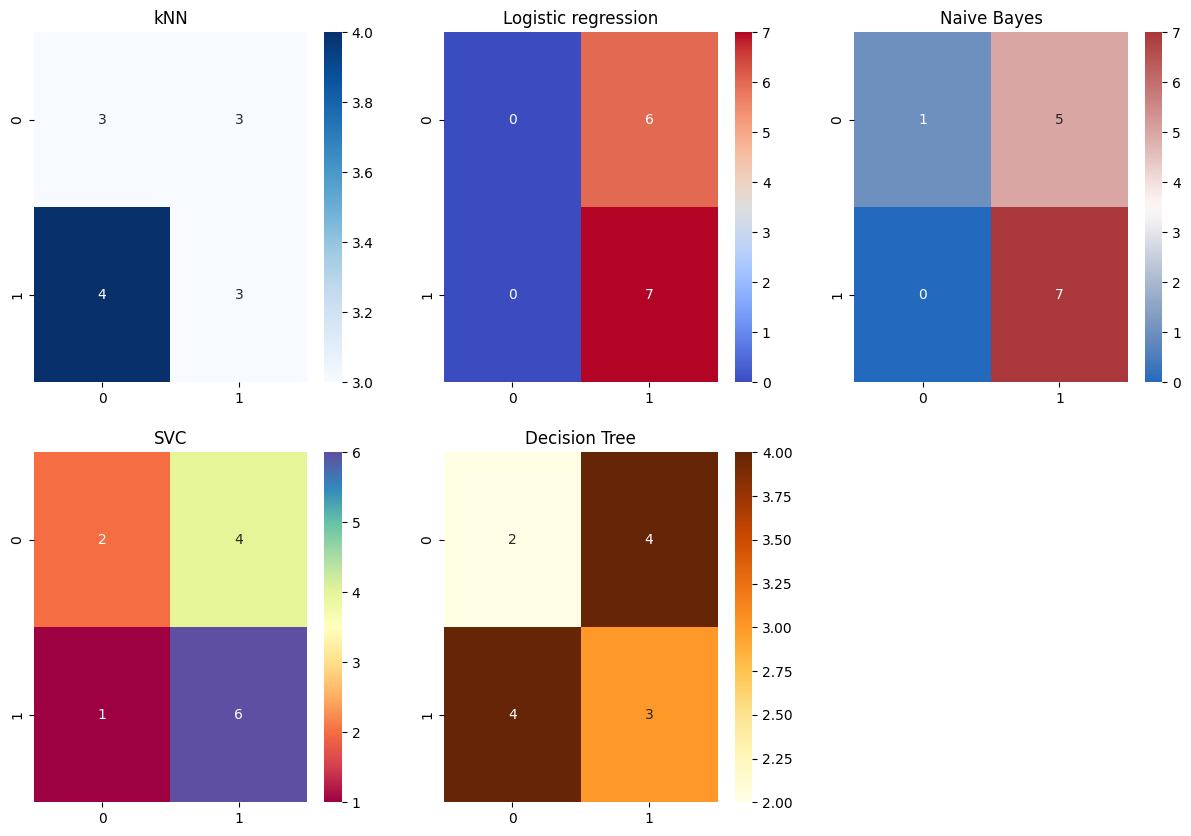

In [32]:
# we visualize the result using heat maps (an "error matrix" is being built).
# the "error matrix" for binary classification is a 2*2 matrix where the columns are correctly predicted

# we look at the main diagonal (cases where the model predicted correctly): 
# at the intersection of [0;0] is the number "0", which the system predicted as "0"
# at the intersection [1;1] is the number "1", which the system predicted as "1"

# look at the side diagonal 
# [0;1], the number of cases where "1" is predicted as "0"
# [1;0], the number of cases where "0" is predicted as "1"

import seaborn as sns
plt.rcParams["figure.figsize"] = 15, 10  # width, height

plt.subplot(2, 3, 1)
sns.heatmap(pd.DataFrame(metrics.confusion_matrix(df_norm.loc[test_index, y_col], y_pred_kNN)),
            annot=True, cmap="Blues") # parameter annot=True records values inside matrix cells, not just color
plt.title("kNN")

plt.subplot(2, 3, 2)
sns.heatmap(pd.DataFrame(metrics.confusion_matrix(df_norm.loc[test_index, y_col], y_pred_logit)),
            annot=True, cmap="coolwarm")
plt.title("Logistic regression")

plt.subplot(2, 3, 3)
sns.heatmap(pd.DataFrame(metrics.confusion_matrix(df_norm.loc[test_index, y_col], y_pred_bayes)),
            annot=True, cmap="vlag")
plt.title("Naive Bayes")

plt.subplot(2, 3, 4)
sns.heatmap(pd.DataFrame(metrics.confusion_matrix(df_norm.loc[test_index, y_col], y_pred_SVC)),
            annot=True, cmap="Spectral")
plt.title("SVC")

plt.subplot(2, 3, 5)
sns.heatmap(pd.DataFrame(metrics.confusion_matrix(df_norm.loc[test_index, y_col], y_pred_tree)),
            annot=True, cmap="YlOrBr")
plt.title("Decision Tree");

# Interpretation: the more numbers on the main diagonal, the better the specific algorithm worked

In [33]:
# Evaluate the quality of these models. "F-measure" is one of the indicators of classification quality
print("F-measure (kNN) =", metrics.f1_score(df_norm.loc[test_index, y_col], y_pred_kNN)) # 2 parameters: true and predicted
print("F-measure (Logistic regression) =", metrics.f1_score(df_norm.loc[test_index, y_col], y_pred_logit))
print("F-measure (Naive Bayes) =", metrics.f1_score(df_norm.loc[test_index, y_col], y_pred_bayes))
print("F-measure (SVC) =", metrics.f1_score(df_norm.loc[test_index, y_col], y_pred_SVC))
print("F-measure (Decision Tree) =", metrics.f1_score(df_norm.loc[test_index, y_col], y_pred_tree))

F-measure (kNN) = 0.4615384615384615
F-measure (Logistic regression) = 0.7000000000000001
F-measure (Naive Bayes) = 0.7368421052631579
F-measure (SVC) = 0.7058823529411764
F-measure (Decision Tree) = 0.42857142857142855


# Clustering task

**Task 9.** Mix and normalize numeric columns and save the results in a new data frame. Perform data clustering using k-means and hierarchical agglomerative methods using normalized columns as factor features. Given the true clustering of the grouping of games by genre, calculate the quality indicators of clustering ARI and silhouette. The results of the hierarchical algorithm are presented in the form of a dendrogram.

In [34]:
# THEORY. Clustering.
# You need to automatically divide the data into several groups (clusters) in order to, 
# so that each group consists of objects similar to each other. Artificial intelligence finds the similarity criterion itself. 
# We can set the number of clusters manually, or artificial intelligence will find them by itself.
# Clustering is teaching without a teacher (the answers are unknown). There is no need for training and test samples

# How, then, to assess the quality of clustering? There is an API metric that uses "true" data partitioning into clusters. 
# In our dataset, "as it were" there is information about the true partition. By the condition of the problem, let the "division of games by genre" be the true division of games into clusters
# i.e. assume that they are already grouped by genre. And then we will compare how our clustering algorithm worked with our true separation
# But most often we don't have this "true" separation!

# X_cols already had all the numeric columns. These will be factor variables. Or you can reassemble them: X_cols = df.columns[[0, 3, 6, 7, 8, 9, 10]]
# as such, there is no "target variable" here!

# mixed and normalized (because inside the calculation of distances between objects is used) data frame for clustering
df_norm_cluster = df[list(X_cols) + ["Genre"]].sample(n=len(df)).copy() # there was no genre in X_cols, so we attach it. And mix
df_norm_cluster[X_cols] = MinMaxScaler().fit_transform(df_norm_cluster[X_cols]) # normalization (but without taking into account the genre, because it is not numeric). But it should be in the data frame
df_norm_cluster.head(3)

# Result: we got a normalized data frame with numeric columns + with a column of true cluster labels ("genre")

,Rank,Year,NorthAmerica_Sales,EurpeanUnion_Sales,Japan_Sales,Other_Sales,Global_Sales,Genre
196,0.991031,1.000000,0.006749,0.129221,0.005871,0.081560,0.000128,Sports
120,0.591928,0.529412,0.061461,0.053756,0.126223,0.117021,0.020903,Role-Playing
99,0.475336,0.470588,0.088696,0.060303,0.138943,0.033097,0.030392,Platform


In [35]:
# manually calculate the "true number of clusters" (the number of different genre values)
clusters_count = len(df_norm_cluster.Genre.unique())
print(clusters_count) # from our point of view, we have 12 groups. Although, perhaps, this is not the case

12


In [36]:
# direct clustering
from sklearn.cluster import AgglomerativeClustering, KMeans # 2 clustering algorithms
from sklearn.metrics import adjusted_rand_score, silhouette_score # calculation of clustering quality indicators

# 1. Algorithm "k-means"
model_kmeans = KMeans(n_clusters=clusters_count, n_init="auto").fit(df_norm_cluster[X_cols]) 
# parameter n_clusters - how many clusters to divide the data into. Let's enter our true value = 12
# n_init="auto" - defines the initial cluster centers for the mathematical algorithm
# we pass only factor columns to fit(). And by the genre column we will check the quality of clustering
# model_kmeans - clustering result
labels_kmeans = model_kmeans.labels_ # cluster labels (these are just ordinal numbers, the separation itself is important (grouping by clusters), not these labels). Unlike classification, where the class label is important
print(labels_kmeans)
# Interpretation: output of "cluster labels" obtained as a result of using the "k-means" algorithm

[ 0  9  1  2  6  0  2  0  5  1 11  3  7 11  9 10 11  1 10  6  6  0 10  8
 10  1  7 10 10  6  5  5  2  0  1  1  6 11 11  0 10  7  3  6  9 10 10  8
  2  2  2  8  3 10  8  1  2 11  0  9  8 10 11  8  1  7  0  9  9  0  3 10
  0  2 11 11  6  0  9 10 11  3  4 10 10  8  3  8  2  6 10  2  5  1  1  9
  6  3  2  9 10 10  6  0  0  9  9  5  9  3  7  6  1  9  6  0  0  2 10  2
  1  6 10  3 10  0  2  2  8  3  2  9  9  8 10  2  5  8  6  2  3 11  2  2
  2  1  6  0  9  7  8  0  1 10  1  6  9  3 11  0  0 10  7  2 10  1  6  2
  8  6  6  9 11 10 10  5  6  6  1  3  9  3  8  2  0  2  7  0 10 10  6  1
  8  2  9  0  2  8 10]


In [37]:
# let's look at the "as it were" true cluster labels. 
df_norm_cluster.Genre.values

array(['Sports', 'Role-Playing', 'Platform', 'Action', 'Action',
       'Role-Playing', 'Shooter', 'Role-Playing', 'Platform', 'Fighting',
       'Platform', 'Sports', 'Shooter', 'Simulation', 'Platform',
       'Sports', 'Platform', 'Platform', 'Shooter', 'Shooter', 'Action',
       'Role-Playing', 'Shooter', 'Misc', 'Action', 'Platform',
       'Platform', 'Action', 'Role-Playing', 'Simulation', 'Action',
       'Puzzle', 'Shooter', 'Role-Playing', 'Racing', 'Platform',
       'Action', 'Action', 'Sports', 'Action', 'Platform', 'Role-Playing',
       'Racing', 'Adventure', 'Racing', 'Sports', 'Shooter', 'Platform',
       'Misc', 'Shooter', 'Shooter', 'Misc', 'Misc', 'Shooter',
       'Fighting', 'Racing', 'Shooter', 'Racing', 'Action',
       'Role-Playing', 'Fighting', 'Shooter', 'Racing', 'Role-Playing',
       'Adventure', 'Platform', 'Fighting', 'Platform', 'Misc', 'Shooter',
       'Platform', 'Platform', 'Sports', 'Platform', 'Platform', 'Puzzle',
       'Action', 'Action', 'P

In [38]:
# Now it is possible to "sort of" correlate the true and predicted using the ARI metric

from sklearn.metrics import adjusted_rand_score, silhouette_score
y_col = "Genre" # "true" data partitioning

# an indicator of the quality of clustering ARI, which shows how close the partition is to the true one
print(f"ARI (k-means) = {adjusted_rand_score(df_norm_cluster[y_col], labels_kmeans)}")
# Interpretation: poor clustering quality (ARI and Silhouette are measured from -1 to 1), because we had an artificial division into clusters "by genre"
# i.e. factorial features that were used to divide into clusters poorly determine the purpose "by genre".
# ARI (k-means) may differ for the data, since the algorithm chooses different cluster centers by itself

ARI (k-means) = 0.06945697768555861


In [39]:
# Now let's look at the "silhouette" metric, which does not use true cluster labels, but looks at the "clarity of the selection" of clusters. The silhouette is also measured from -1 to 1
print(f"silhouette (k-means) = {silhouette_score(X=df_norm_cluster[X_cols], labels=labels_kmeans)}") # at the input of the function: the data itself and the predicted labels
# Interpretation: the result is still better. Clusters are not very clearly highlighted

silhouette (k-means) = 0.29096532095585054


In [40]:
# 2. Algorithm "hierarchical agglomerative method"
model_agglo = AgglomerativeClustering(n_clusters=clusters_count).fit(df_norm_cluster[X_cols])
labels_agglo = model_agglo.labels_  # predicted class labels
print(labels_agglo)

[ 0 10 10 11  6  0 11  0  5 10  4  3  7  4  4  6  5 10  6  6  6  0  1  1
  6 10  2  1  1  6  5  5  1  0  2  2  6  4  4  0  1  8  3  6  4  1  1  1
  1 11 11  1  3  6  1  2 11  4  0  0  1  6  4  1  2  2  0  4  4  0  3  6
  0  1  5  5  6  0 10  6  4  3  9  1  1  2  8  1  1  0  1 11  4 10  2 10
  6  3  1  4  1  6  6  0  0 10  4  5  4  8  8  6  2  4  6  0  0 11  1  1
  2  6 10  3  1  0  1 11  1  3  1  4  4  8  6 11  5  1  6  3  3  4  1 11
  1  2  6  0  4  7  1  0 10  6  2  6  0  8  4  0  0  6  7 11  1  2  0 11
  1  6  0  4  4  6  6  5  6 10  2  8 10  3  1 11  0 11  2  0  6  6  6 10
  1  1  4  0  3  1  1]


In [41]:
print(f"ARI (agglomerative) = {adjusted_rand_score(df_norm_cluster[y_col], labels_agglo)}")
print(f"silhouette (agglomerative) = {silhouette_score(X=df_norm_cluster[X_cols], labels=labels_agglo)}")

ARI (agglomerative) = 0.064729085174444
Силуэт (agglomerative) = 0.26405739108776444


In [42]:
# Building a dendrogram
from scipy.cluster.hierarchy import dendrogram

def plot_dendrogram(model, **kwargs):
  # Children of hierarchical clustering
  children = model.children_

  # Distances between each pair of children
  # Since we don't have this information, we can use a uniform one for plotting
  distance = np.arange(children.shape[0])
  
  # The number of observations contained in each cluster level
  no_of_observations = np.arange(2, children.shape[0]+2)
  
  # Create linkage matrix and then plot the dendrogram
  linkage_matrix = np.column_stack([children, distance, no_of_observations]).astype(float)
  
  # Plot the corresponding dendrogram
  dendrogram(linkage_matrix, **kwargs)

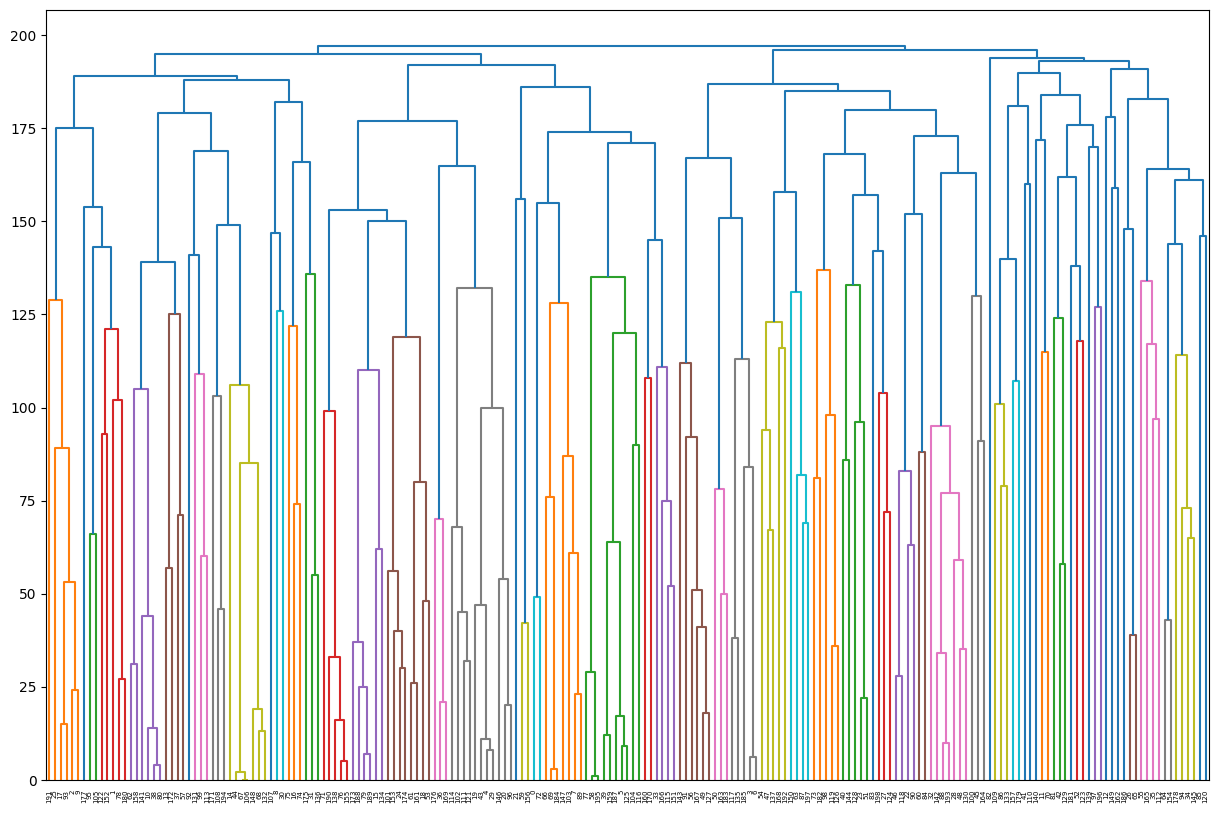

In [43]:
plot_dendrogram(model_agglo) # we present the "hierarchical agglomerative model" created by us for input. 
# The algorithm combines the nearest objects in pairs (at the initial stage, the total number of objects is calculated (objects are listed on the X axis)), then again, etc.
# These associations are displayed as a dendrogram
# on the Y axis - the distance between the objects to be combined

# As a result, we combined everything into 1 large cluster.

# With the help of the "k-means" algorithm, such a visualization cannot be constructed

**Task 10.** Go through the different values of the number of clusters and try to find one in which the clustering quality indicators will be higher than with the true number of clusters.

In [44]:
# let's iterate over the number of clusters from 2 to 30
for clusters_count in range(2, 31):
  model_kmeans = KMeans(n_clusters=clusters_count, n_init="auto").fit(df_norm_cluster[X_cols])
  labels_kmeans = model_kmeans.labels_
  
  model_agglo = AgglomerativeClustering(n_clusters=clusters_count).fit(df_norm_cluster[X_cols])
  labels_agglo = model_agglo.labels_
  
  print(f"Number of clusters = {clusters_count}")
  print(f"\tk-means, ARI = {adjusted_rand_score(df_norm_cluster[y_col], labels_kmeans)},"
        f" silhouette = {silhouette_score(X=df_norm_cluster[X_cols], labels=labels_kmeans)}")
  print(f"\tAgglomerative, ARI = {adjusted_rand_score(df_norm_cluster[y_col], labels_agglo)},"
        f" silhouette = {silhouette_score(X=df_norm_cluster[X_cols], labels=labels_agglo)}")

Number of clusters = 2
	k-means, ARI = 0.015937003584457113, silhouette = 0.3542235801868949
	Agglomerative, ARI = 0.014242746786615789, silhouette = 0.3494747012764459
Number of clusters = 3
	k-means, ARI = 0.047723392488908625, silhouette = 0.33123354436682334
	Agglomerative, ARI = 0.033707233806553834, silhouette = 0.3012168621790673
Number of clusters = 4
	k-means, ARI = 0.05412757017375049, silhouette = 0.3220907084779618
	Agglomerative, ARI = 0.06851693654430248, silhouette = 0.3056908181124318
Number of clusters = 5
	k-means, ARI = 0.04723213023310688, silhouette = 0.2651282292698866
	Agglomerative, ARI = 0.06931417225625294, silhouette = 0.3125010504738747
Number of clusters = 6
	k-means, ARI = 0.07432576494253616, silhouette = 0.3418640169171163
	Agglomerative, ARI = 0.07185207096972485, silhouette = 0.3308230958064636
Number of clusters = 7
	k-means, ARI = 0.0824346322958254, silhouette = 0.3474802352406452
	Agglomerative, ARI = 0.06885639556944863, silhouette = 0.28666875234